<a href="https://colab.research.google.com/github/sampath0711/DEEP-LEARNING/blob/main/Skill/Skill-1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ultralytics opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 26.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from google.colab import files

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

print("VisionPort model loaded successfully!")

VisionPort model loaded successfully!


In [4]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded:", image_path)

Saving Hyderabad Rush Hour Crossing.png to Hyderabad Rush Hour Crossing.png
Image uploaded: Hyderabad Rush Hour Crossing.png


In [5]:
# Detect objects in the image
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

print("Object detection completed!")


image 1/1 /content/Hyderabad Rush Hour Crossing.png: 384x640 7 persons, 7 cars, 2 motorcycles, 2 buss, 1 backpack, 318.3ms
Speed: 22.5ms preprocess, 318.3ms inference, 36.5ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict
Object detection completed!


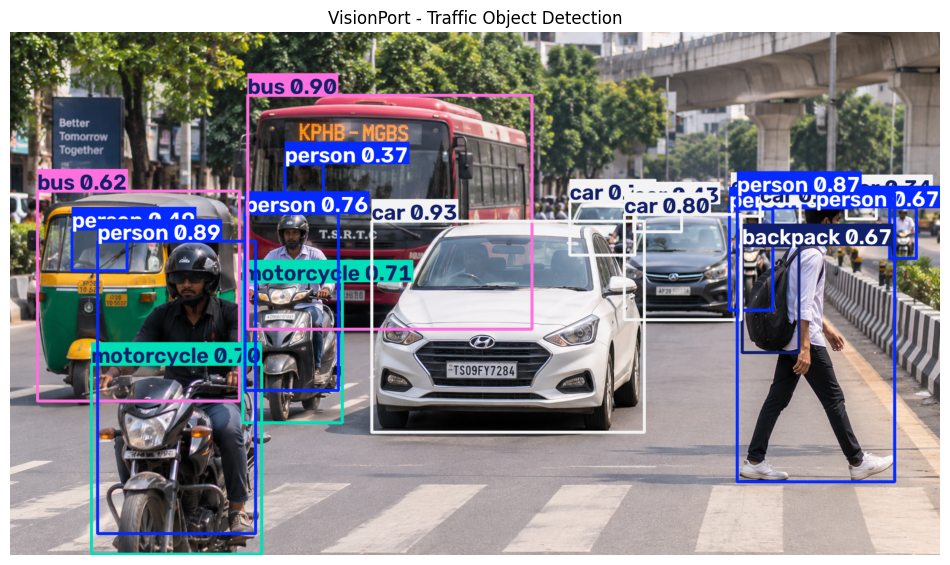

In [6]:
# Get image with bounding boxes
output_image = results[0].plot()

# Convert BGR to RGB
output_image = cv2.cvtColor(
    output_image,
    cv2.COLOR_BGR2RGB
)

# Display image
plt.figure(figsize=(12, 8))
plt.imshow(output_image)
plt.axis("off")
plt.title("VisionPort - Traffic Object Detection")
plt.show()

In [7]:
for box in results[0].boxes:

    class_id = int(box.cls[0])

    object_name = model.names[class_id]

    confidence = float(box.conf[0])

    print(
        "Object:", object_name,
        "| Confidence:", round(confidence * 100, 2), "%"
    )

Object: car | Confidence: 92.74 %
Object: bus | Confidence: 90.31 %
Object: person | Confidence: 88.62 %
Object: person | Confidence: 87.05 %
Object: car | Confidence: 79.68 %
Object: person | Confidence: 76.23 %
Object: motorcycle | Confidence: 71.11 %
Object: motorcycle | Confidence: 70.04 %
Object: backpack | Confidence: 66.85 %
Object: person | Confidence: 66.69 %
Object: bus | Confidence: 62.49 %
Object: car | Confidence: 59.08 %
Object: person | Confidence: 51.14 %
Object: person | Confidence: 49.05 %
Object: car | Confidence: 43.0 %
Object: person | Confidence: 37.47 %
Object: car | Confidence: 37.09 %
Object: car | Confidence: 33.75 %
Object: car | Confidence: 25.15 %
